In [29]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import talib as ta
import numpy as np

from sklearn.metrics import mean_absolute_percentage_error
from torch.utils.data import DataLoader, TensorDataset

In [13]:
class RecurrentNeuralNetworkRegressor(nn.Module):
    def __init__(self, input_dim, hidden_dim, layer_dim, dropout=0.3, block_type='GRU'):
        assert block_type in ['LSTM', 'GRU'], 'Error: unknown type of recurrent block.'
        
        super(RecurrentNeuralNetworkRegressor, self).__init__()
        self.hidden_dim = hidden_dim
        self.layer_dim = layer_dim

        if block_type == 'LSTM':
            self.rec_block = nn.LSTM(input_dim, hidden_dim, layer_dim, dropout=dropout, batch_first=True)
        else:
            self.rec_block = nn.GRU(input_dim, hidden_dim, layer_dim, dropout=dropout, batch_first=True)

        for name, param in self.rec_block.named_parameters():
            if 'weight' in name:
                nn.init.orthogonal_(param.data)
            elif 'bias' in name:
                nn.init.normal_(param.data)

        self.layer_norm = nn.LayerNorm(hidden_dim)
        nn.init.normal_(self.layer_norm.weight)
        nn.init.normal_(self.layer_norm.bias)
        
        self.linear1 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.linear2 = nn.Linear(hidden_dim // 2, 1)
        
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        
        for layer in [self.linear1, self.linear2]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.constant_(layer.bias, 0.1)

    def forward(self, x):
        out, _ = self.rec_block(x)
        out = self.layer_norm(out[:, -1, :])
        out = self.relu(self.linear1(out))
        out = self.dropout(out)
        out = self.relu(self.linear2(out))
        
        return out.squeeze()

In [14]:
def load_sberbank():
    df = pd.read_csv(r'..\..\resource\sberbank_stock_prices.csv', delimiter=';', dtype={'<DATE>' : str})
    df = df[['<DATE>', '<CLOSE>']]
    name_map = {column:column[1:-1].capitalize() for column in df.columns.tolist()}
    df = df.rename(columns=name_map)
    df['Date'] = pd.to_datetime(df['Date'], format='%y%m%d')
    df.set_index('Date', inplace=True)

    return df

In [23]:
def create_ta_features(df):
    ROLLING_STD = 11
    ROLLING_MEAN = 11
    EMA_TIME_PERIOD = 9
    RSI_TIME_PERIOD = 9
    TARGET_NAME = 'Close'

    new_df = df.copy()
    new_df[f'EMA_{EMA_TIME_PERIOD}'] = ta.EMA(new_df[TARGET_NAME].shift(1), timeperiod=EMA_TIME_PERIOD)
    new_df[f'RSI_{RSI_TIME_PERIOD}'] = ta.RSI(new_df[TARGET_NAME].shift(1), timeperiod=RSI_TIME_PERIOD)
    new_df[f'Std_{ROLLING_STD}'] = new_df[TARGET_NAME].shift(1).rolling(ROLLING_STD).std()
    new_df[f'Mean_{ROLLING_MEAN}'] = new_df[TARGET_NAME].shift(1).rolling(ROLLING_MEAN).mean()
    new_df['Price_change'] = new_df[TARGET_NAME].shift(1).pct_change()
    new_df.dropna(inplace=True)

    return new_df

In [24]:
def create_sequences(X, y, seq_length=10):
    X_seq, y_seq = [], []

    for i in range(X.shape[0] - seq_length):
        X_seq.append(X.iloc[i:i + seq_length])
        y_seq.append(y.iloc[i + seq_length])

    return np.array(X_seq), np.array(y_seq)

In [25]:
seq_length = 10
data = load_sberbank()
data = create_ta_features(data)
X, y = data.drop('Close', axis=1), data['Close']
X, y = create_sequences(X, y, seq_length)
threshold = int(0.8 * X.shape[0])
X_train, y_train, X_test, y_test = X[:threshold], y[:threshold], X[threshold:], y[threshold:]

In [26]:
params = {
    'input_dim' : 5, 
    'hidden_dim' : 256, 
    'layer_dim' : 4
}

block_type = 'LSTM'

num_epochs = 200
batch_size = 32

val_threshold = int(X_train.shape[0] * 0.8)

X_train_tensor = torch.FloatTensor(X_train[:val_threshold])
y_train_tensor = torch.FloatTensor(y_train[:val_threshold])

X_val_tensor = torch.FloatTensor(X_train[val_threshold:])
y_val_tensor = torch.FloatTensor(y_train[val_threshold:])

X_test_tensor = torch.FloatTensor(X_test)
y_test_tensor = torch.FloatTensor(y_test)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

model = RecurrentNeuralNetworkRegressor(params['input_dim'], 
                                        params['hidden_dim'], 
                                        params['layer_dim'],
                                        block_type=block_type)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
min_val_loss = float('inf')

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    for X_batch, y_batch in train_loader:
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item()
    
    train_loss /= len(train_loader)

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            val_loss += loss.item()
        val_loss /= len(val_loader)

    if min_val_loss > val_loss:
        min_val_loss = val_loss
        torch.save(model, block_type + '_regressor.pth')

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{num_epochs} - Train loss: {train_loss}, Val loss: {val_loss}")

Epoch 5/200 - Train loss: 44157.416015625, Val loss: 60719.41127232143
Epoch 10/200 - Train loss: 29864.097862830527, Val loss: 42294.07114955357
Epoch 15/200 - Train loss: 18527.280423091008, Val loss: 26801.04129464286
Epoch 20/200 - Train loss: 12443.703308105469, Val loss: 18492.048828125
Epoch 25/200 - Train loss: 9469.786445030799, Val loss: 12955.909737723214
Epoch 30/200 - Train loss: 7293.959648719201, Val loss: 8770.87339564732
Epoch 35/200 - Train loss: 4647.311841524564, Val loss: 5232.751656668527
Epoch 40/200 - Train loss: 2519.200836768517, Val loss: 1780.4880572727748
Epoch 45/200 - Train loss: 1868.8824756328877, Val loss: 908.3449979509626
Epoch 50/200 - Train loss: 1634.5385061410757, Val loss: 645.7721851893833
Epoch 55/200 - Train loss: 1528.2263201200044, Val loss: 585.6346375601632
Epoch 60/200 - Train loss: 1622.813629737267, Val loss: 567.1341067722866
Epoch 65/200 - Train loss: 1282.449703509991, Val loss: 426.6767349243164
Epoch 70/200 - Train loss: 1173.6892

In [27]:
def test_plot(y_pred, y_test, dates) -> None:
    df = pd.DataFrame({'Date': dates, 'True_close': y_test, 'Pred_close': y_pred})

    plt.figure(figsize=(12, 6))
    sns.lineplot(data=df, x='Date', y='True_close', color='blue', label='Фактические значения (y_test)', linewidth=2)
    sns.lineplot(data=df, x='Date', y='Pred_close', color='red', marker='o', label='Предсказанные значения (y_pred)', linewidth=2)
    plt.title('Сравнение фактических и предсказанных значений', fontsize=14, fontweight='bold')
    plt.xlabel('Дата', fontsize=12)
    plt.ylabel('Значения', fontsize=12)
    plt.legend(fontsize=10)
    plt.xticks(rotation=45)
    
    plt.gcf().autofmt_xdate()
    
    plt.tight_layout()
    plt.show()

0.032424027729364084


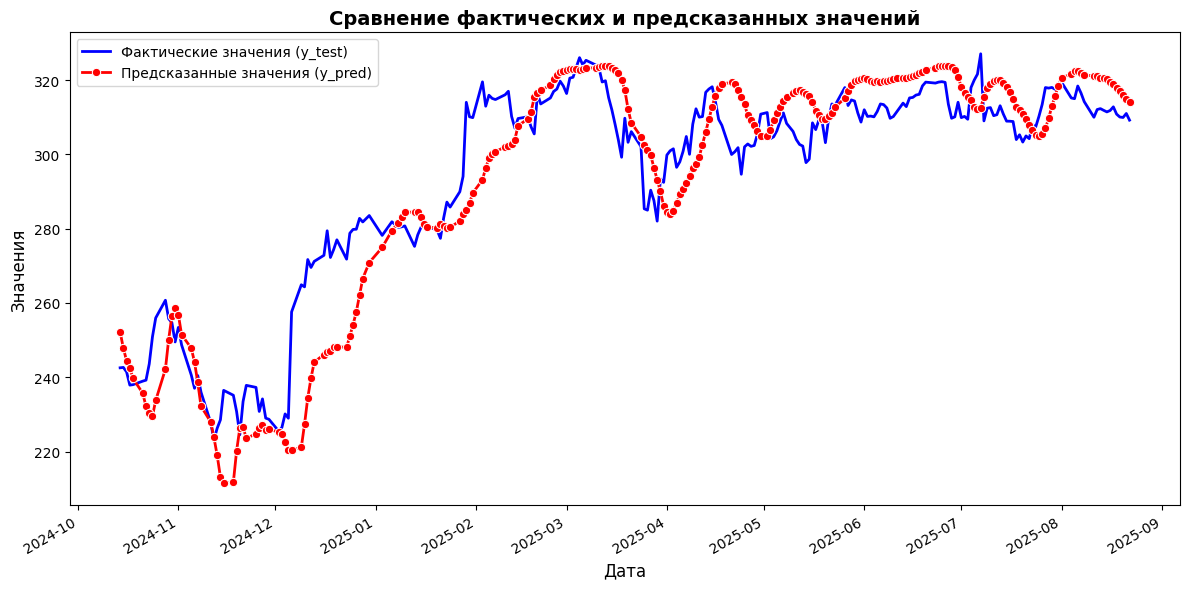

In [28]:
model = torch.load(block_type + '_regressor.pth', weights_only=False)
model.eval()
with torch.no_grad():
    y_pred = model(X_test_tensor).detach().numpy()
    print(mean_absolute_percentage_error(y_pred, y_test))
    dates = data.index[:data.shape[0] - seq_length][threshold:]
    test_plot(y_pred, y_test, dates)